In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import torch



In [4]:
torch.cuda.is_available()

True

In [5]:
from diffusers import SemanticStableDiffusionPipeline

In [6]:
pipe = SemanticStableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16
).to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The SemanticStableDiffusionPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 


In [7]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

NUM_INFERENCE_STEPS = 50
GUIDANCE_SCALE = 7.5
MAX_ITER_TO_ALTER = 25
EDIT_GUIDANCE_SCALE=5.0,
EDIT_WARMUP_STEPS=10,
EDIT_THRESHOLD=0.9,
SEEDS = [10, 20, 30, 40, 50]

PROMPTS = [
    {
        "prompt": "a cat and a frog",
        "editing_prompt": ["green frog","black cat"],
        "objects": ["cat", "frog"],
    },
    {
        "prompt": "a banana and an apple",
        "editing_prompt": ["yellow banana", "red apple"],
        "objects": ["banana", "apple"],
    },
    {
        "prompt": "a black motorcycle and a red sports car",
        "objects": ["motorcycle", "car"],
        "editing_prompt": ["red car", "black motorcyle"]
    },
    # Add more prompts only after checking their token indices:
    # {"prompt": "a dog and a bicycle", "objects": ["dog", "bicycle"],
    #  "token_indices": [...]},
]

for item in PROMPTS:
    print("\\nPrompt:", item["prompt"])

pipe.set_progress_bar_config(disable=True)

\nPrompt: a cat and a frog
\nPrompt: a banana and an apple
\nPrompt: a black motorcycle and a red sports car


In [8]:
prompt = "a cat and a frog"

seed = 6141
generator = torch.Generator("cuda").manual_seed(seed)

images = pipe(
    prompt=prompt,
    num_inference_steps=50,
    guidance_scale=7.5,

    # Semantic concept to encourage
    editing_prompt=["green frog"],

    # False means move toward the concept
    reverse_editing_direction=[False],

    # Parameters controlling the semantic guidance
    edit_guidance_scale=[5.0],
    edit_warmup_steps=[10],
    edit_threshold=[0.9],

    generator=generator,
    
).images

image = images[0]

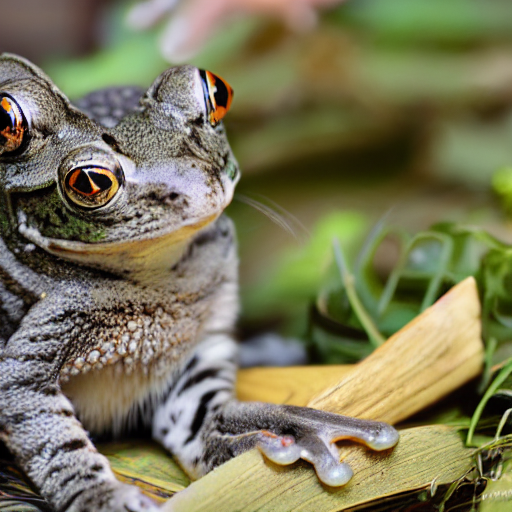

In [9]:
image

In [10]:
%pip install open_clip_torch -q

Note: you may need to restart the kernel to use updated packages.


In [11]:
import open_clip
from transformers import pipeline as hf_pipeline

In [12]:
import time

In [13]:
OUTPUT_DIR = "/kaggle/working/sega_evaluation"
IMAGE_DIR = os.path.join(OUTPUT_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

In [14]:
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k"
)
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(DEVICE).eval()

detector = hf_pipeline(
    task="zero-shot-object-detection",
    model="IDEA-Research/grounding-dino-tiny",
    device=0 if DEVICE == "cuda" else -1,
)

@torch.no_grad()
def clip_scores(image, prompt, objects):
    texts = [prompt] + [f"a photo of a {obj}" for obj in objects]
    image_tensor = clip_preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    text_tokens = clip_tokenizer(texts).to(DEVICE)

    image_features = clip_model.encode_image(image_tensor)
    text_features = clip_model.encode_text(text_tokens)
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    scores = (image_features @ text_features.T).squeeze(0).float().cpu().tolist()
    result = {
        "clip_full_prompt": scores[0],
        "clip_min_object": min(scores[1:]) if len(scores) > 1 else scores[0],
    }
    for obj, score in zip(objects, scores[1:]):
        result[f"clip_{obj.replace(' ', '_')}"] = score
    return result

def detect_objects(image, objects, threshold=0.25):
    # Grounding DINO's zero-shot pipeline expects candidate labels.
    predictions = detector(
        image.convert("RGB"),
        candidate_labels=objects,
        threshold=threshold,
    )

    detected = set()
    best_scores = {obj: 0.0 for obj in objects}

    for pred in predictions:
        label = str(pred.get("label", "")).lower().strip()
        score = float(pred.get("score", 0.0))
        if label in best_scores:
            best_scores[label] = max(best_scores[label], score)
            if score >= threshold:
                detected.add(label)

    result = {
        "all_objects_detected": int(all(obj.lower() in detected for obj in objects)),
        "detected_objects": ",".join(sorted(detected)),
    }
    for obj in objects:
        result[f"det_{obj.replace(' ', '_')}"] = int(obj.lower() in detected)
        result[f"det_score_{obj.replace(' ', '_')}"] = best_scores[obj]
    return result

print("CLIP and Grounding DINO loaded.")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

CLIP and Grounding DINO loaded.


In [15]:
records = []

for item in PROMPTS:
    prompt = item["prompt"]
    objects = [obj.lower() for obj in item["objects"]]
    editing_prompt = item["editing_prompt"]

    for seed in SEEDS:
        generator = torch.Generator(device=DEVICE).manual_seed(seed)
        
        if DEVICE == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        images = pipe(
                prompt=prompt,
                guidance_scale=GUIDANCE_SCALE,
                generator=generator,
                num_inference_steps=NUM_INFERENCE_STEPS,
                editing_prompt=editing_prompt, 
                reverse_editing_direction=[False, False],
                edit_guidance_scale=[5.0,5.0],
                edit_warmup_steps=[10,10],
                edit_threshold=[0.9,0.9],
            ).images
        image = images[0]
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        safe_prompt = "".join(
            ch if ch.isalnum() else "_" for ch in prompt
        ).strip("_")
        image_path = os.path.join(
            IMAGE_DIR, f"{safe_prompt}_seed{seed}.png"
        )
        image.save(image_path)

        row = {
            "prompt": prompt,
            "seed": seed,
            "image_path": image_path,
            "generation_seconds": elapsed,
            "guidance_scale": GUIDANCE_SCALE,
            "num_inference_steps": NUM_INFERENCE_STEPS,
        }

        row.update(clip_scores(image, prompt, objects))
        row.update(detect_objects(image, objects))
        records.append(row)

        # Save after each image so progress is not lost.
        pd.DataFrame(records).to_csv(
            os.path.join(OUTPUT_DIR, "per_image_results.csv"),
            index=False,
        )

        del image, generator
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
            

print("Finished. Images and per-image CSV saved in:", OUTPUT_DIR)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Finished. Images and per-image CSV saved in: /kaggle/working/sega_evaluation
